# Week 7: Hands-On ML Solution Data Visualizations

## Dataset 2: Customer Transactions

### 1. Introduction

In this notebook, our team explores customer purchasing activity using the cleaned transaction dataset from Milestone 1. We will analyze transaction amounts, product categories, payment methods, and monthly activity to identify useful patterns that may support future machine learning tasks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Loading the Cleaned Dataset

Our team will use the preprocessed transaction dataset from Milestone 1 so we can focus on data analysis and visualization instead of repeating the cleaning process.

In [2]:
transactions = pd.read_csv(
    "customer_transactions_preprocessed.csv"
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


### 3. Initial Dataset Inspection

We will examine the dataset's structure, column types, missing values, and duplicate records to understand the available data before proceeding with our analysis.

In [3]:
display(transactions.head())

print("Dataset shape:", transactions.shape)

print("\nColumn names:")
print(transactions.columns.tolist())

print("\nData types:")
print(transactions.dtypes)

print("\nMissing values:")
print(transactions.isnull().sum())

print("\nDuplicate rows:", transactions.duplicated().sum())

,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod
0,60567026-f719-4cd6-849e-137e86d8938f,5ff75116-0a50-4d04-80fb-31e5ccbb0769,2024-05-15,117.64,Clothing,PayPal
1,4090ba85-b111-4f75-a792-c777965f5255,2c39b9fe-ff57-4d39-9321-9f5cdf187aa1,2023-04-26,466.14,Health & Beauty,Bank Transfer
2,9223891b-73ff-4d5c-b8ae-13ece82ee28b,f79588dd-3db9-4ffa-97f8-7de0e64259f1,2022-09-23,563.99,Clothing,Debit Card
3,9243eebc-938f-480c-8564-16d503d250de,401c0fc9-60df-4455-ad78-67c132f9897d,2024-04-15,254.44,Automotive,PayPal
4,6e3e8eb8-bc0f-4ffe-9f74-5d5efec9502f,2034aebc-8280-4254-a667-92bcd1c2be4f,2024-03-06,590.52,Home & Garden,Bank Transfer


Dataset shape: (3015, 6)

Column names:
['CustomerID', 'TransactionID', 'TransactionDate', 'Amount', 'ProductCategory', 'PaymentMethod']

Data types:
CustomerID             str
TransactionID          str
TransactionDate        str
Amount             float64
ProductCategory        str
PaymentMethod          str
dtype: object

Missing values:
CustomerID         0
TransactionID      0
TransactionDate    0
Amount             0
ProductCategory    0
PaymentMethod      0
dtype: int64

Duplicate rows: 0


### 4. Descriptive Statistics of Transaction Amounts

Our team will calculate key statistics for transaction amounts, including the mean, median, standard deviation, variance, minimum, maximum, range, and quartiles. These measures will help us understand typical transaction values and how much they vary.

In [4]:
amount = pd.to_numeric(
    transactions["Amount"],
    errors="coerce"
).dropna().to_numpy()

amount_statistics = {
    "Valid Amount Count": len(amount),
    "Mean": np.mean(amount),
    "Median": np.median(amount),
    "Standard Deviation": np.std(amount, ddof=1),
    "Variance": np.var(amount, ddof=1),
    "Minimum": np.min(amount),
    "Maximum": np.max(amount),
    "Range": np.ptp(amount),
    "25th Percentile": np.percentile(amount, 25),
    "75th Percentile": np.percentile(amount, 75)
}

for statistic, value in amount_statistics.items():
    if statistic == "Valid Amount Count":
        print(f"{statistic}: {value}")
    else:
        print(f"{statistic}: {value:,.2f}")

Valid Amount Count: 3015
Mean: 490.50
Median: 496.62
Standard Deviation: 283.28
Variance: 80,249.54
Minimum: -100.00
Maximum: 999.86
Range: 1,099.86
25th Percentile: 254.54
75th Percentile: 720.39


### 5. Visualization 1: Transaction Amount Distribution

We will use a histogram to examine how transaction amounts are distributed. This visualization will help our team identify common spending ranges and determine whether transaction values are concentrated or widely spread.

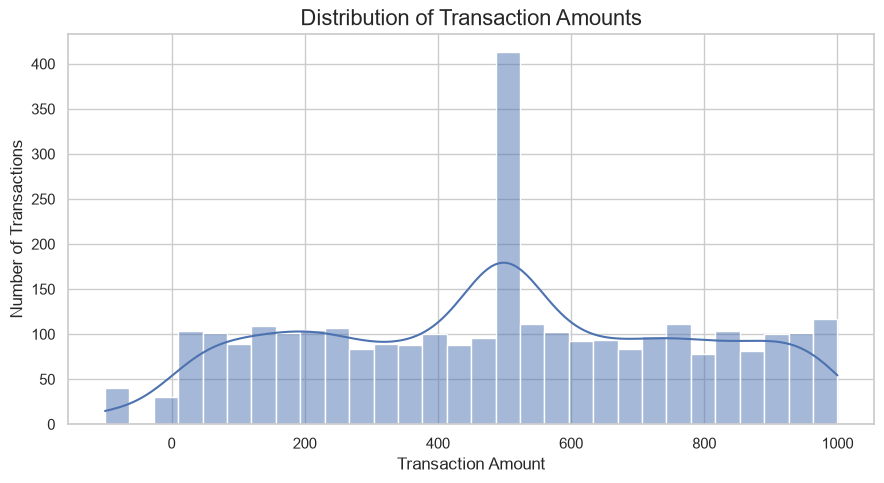

In [6]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=transactions,
    x="Amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Transaction Amounts", fontsize=16)
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### 6. Interpretation of Transaction Amount Distribution

Our histogram shows that transaction amounts vary widely, with a noticeable concentration around 500. Most other amount ranges have fairly similar frequencies, while a small number of transactions have negative values. This suggests that customer spending is diverse, and the negative amounts may need further checking to understand whether they represent refunds or adjustments.

### 7. Visualization 2: Transaction Amount Outliers

Our team will use a boxplot to examine the spread of transaction amounts and identify potential outliers. This will help us check whether unusually low or high values may affect the results of our analysis.

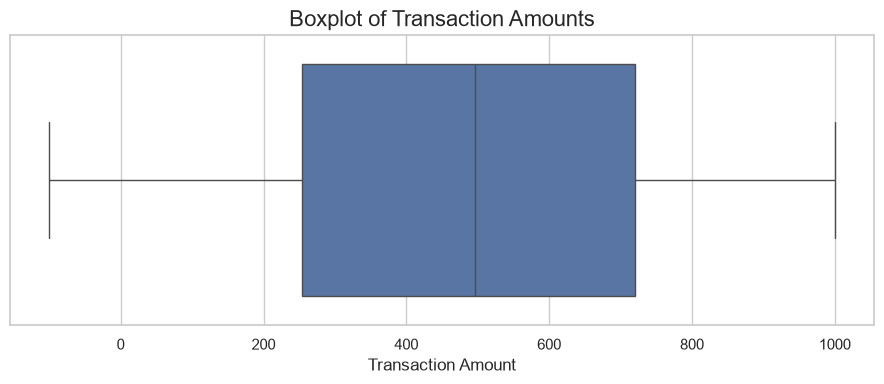

In [7]:
plt.figure(figsize=(9, 4))

sns.boxplot(data=transactions, x="Amount")

plt.title("Boxplot of Transaction Amounts", fontsize=16)
plt.xlabel("Transaction Amount")
plt.tight_layout()
plt.show()

### 8. Interpretation of Transaction Amount Outliers

Our boxplot shows that transaction amounts range from approximately -100 to 1,000, with a median near 500. The middle 50% of values fall roughly between 250 and 720. No separate outlier points are visible, but the negative amounts should still be checked to determine whether they represent refunds or transaction adjustments.

### 9. Visualization 3: Transactions by Product Category

Our team will compare the number of transactions across product categories using a bar chart. This will help us identify which categories are most common and whether purchasing activity is balanced across categories.

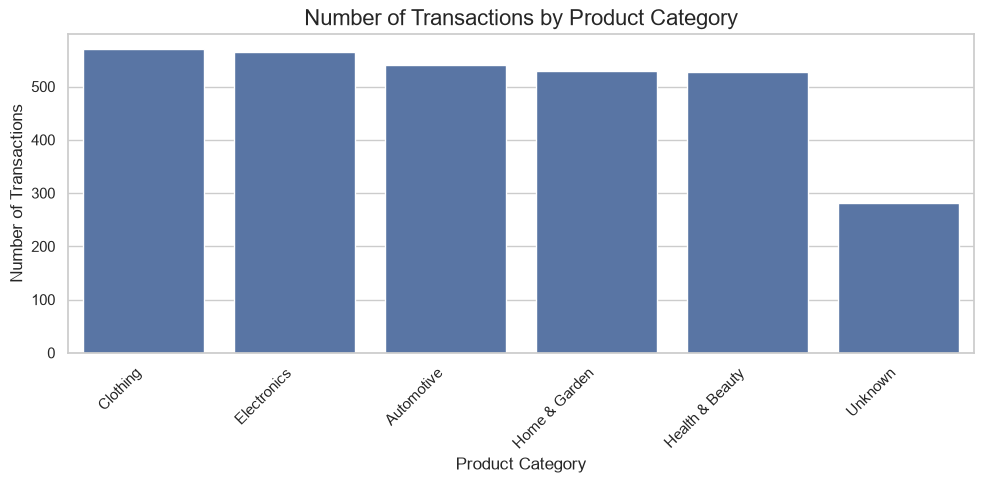

In [8]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=transactions,
    x="ProductCategory",
    order=transactions["ProductCategory"].value_counts().index
)

plt.title("Number of Transactions by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 10. Interpretation of Transactions by Product Category

Our team observed that Clothing and Electronics have the highest number of transactions, followed by Automotive, Home & Garden, and Health & Beauty. The Unknown category has the lowest count by a clear margin. This suggests that purchasing activity is concentrated more in the five identified categories, while the Unknown records may need further review to understand why their product categories are not specified.

### 11. Visualization 4: Transactions by Payment Method

Our team will compare the frequency of each payment method using a bar chart. This will help us identify the most commonly used payment options and see whether customers show a clear preference for a particular method.

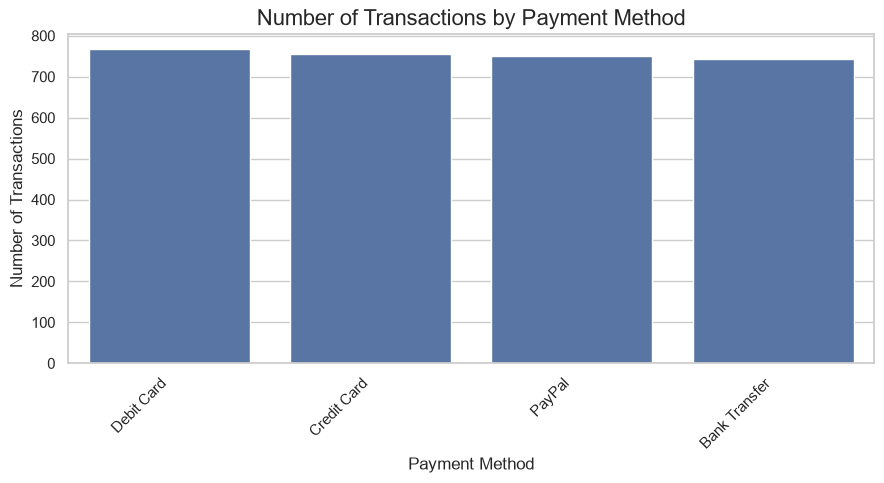

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=transactions,
    x="PaymentMethod",
    order=transactions["PaymentMethod"].value_counts().index
)

plt.title("Number of Transactions by Payment Method", fontsize=16)
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 12. Interpretation of Transactions by Payment Method

Our team observed that Debit Card has the highest number of transactions, followed by Credit Card and PayPal, while Bank Transfer has the lowest count. However, the differences are small, suggesting that customers use the four payment methods at relatively similar rates. This information may help us understand customer payment preferences when analyzing transaction behavior.

### 13. Visualization 5: Monthly Transaction Trends

Our team will examine transaction activity over time to identify months with higher or lower purchasing activity. This can help us recognize possible trends and determine whether transaction volume changes across the observed period.

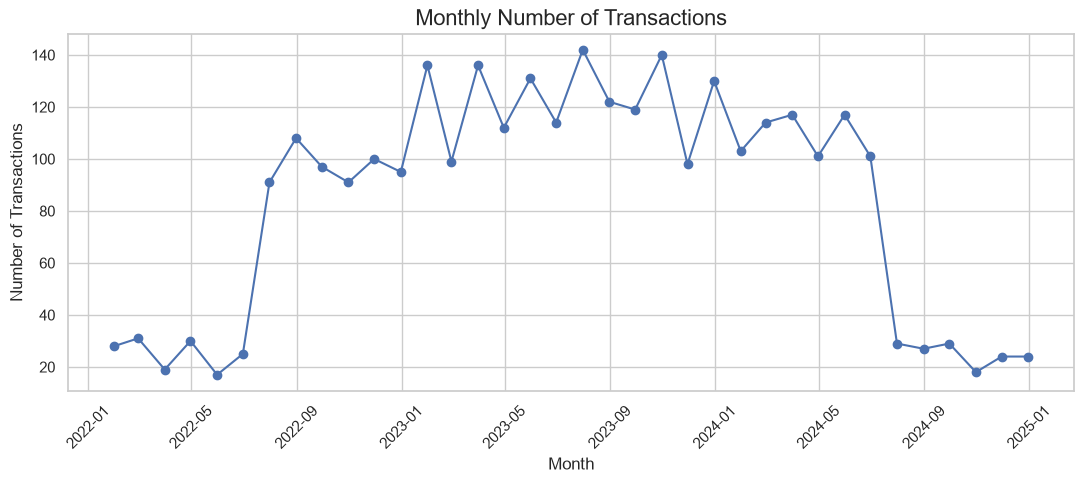

In [10]:
# Convert the transaction date into datetime format
transactions["TransactionDate"] = pd.to_datetime(
    transactions["TransactionDate"],
    errors="coerce"
)

# Group transactions by month
monthly_transactions = (
    transactions.dropna(subset=["TransactionDate"])
    .set_index("TransactionDate")
    .resample("ME")
    .size()
)

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_transactions.index,
    monthly_transactions.values,
    marker="o"
)

plt.title("Monthly Number of Transactions", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 14. Interpretation of Monthly Transaction Trends

Our team observed that monthly transactions increased significantly around mid-2022 and remained generally higher throughout 2023 and the first half of 2024. The highest activity occurred around mid-to-late 2023, reaching approximately 140 transactions in some months. However, transaction counts dropped sharply in the second half of 2024. We should check whether this decline reflects an actual change in customer activity or incomplete records in the dataset.

## 15. Overall Findings and Machine Learning Relevance

Our analysis shows that transaction amounts vary widely, Clothing and Electronics have the highest transaction counts, and customers use different payment methods at relatively similar rates. Monthly activity also changes over time, with a noticeable decline in late 2024. These findings can help guide future machine learning work involving customer purchasing behavior, product preferences, and transaction trends. Before modeling, our team should review negative transaction amounts, Unknown product categories, and the sharp decline in recent monthly records.